# Insurance Claims & Portfolio Risk Dashboard

| Column | Meaning |
|---|---|
| IDpol |  policy ID |
| ClaimNb | number of claims during exposure |
| Exposure | exposure period in years |
| VehPower | vehicle power |
| VehAge | vehicle age |
| DrivAge | driver age |
| BonusMalus | bonus/malus score |
| VehBrand | vehicle-brand category |
| VehGas | fuel type|
| Area | density category from rural to urban |
| Density | population density |
| Region | policy region |
| ClaimAmount | claim cost in the severity table |

## Import Libraries

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
df = pd.read_csv("freMTPL2freq.csv")
df.head()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


In [58]:
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

Rows: 678013
Columns: 12


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  object 
 8   VehGas      678013 non-null  object 
 9   Area        678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(2), int64(6), object(4)
memory usage: 62.1+ MB


In [60]:
df.describe().round(3)

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,678013.000,678013.000,678013.000,678013.000,678013.000,678013.000,678013.000,678013.000
mean,2621856.921,0.053,0.529,6.455,7.044,45.499,59.762,1792.422
std,1641782.753,0.240,0.364,2.051,5.666,14.137,15.637,3958.647
min,1.000,0.000,0.003,4.000,0.000,18.000,50.000,1.000
25%,1157951.000,0.000,0.180,5.000,2.000,34.000,50.000,92.000
50%,2272152.000,0.000,0.490,6.000,6.000,44.000,50.000,393.000
75%,4046274.000,0.000,0.990,7.000,11.000,55.000,64.000,1658.000
max,6114330.000,16.000,2.010,15.000,100.000,100.000,230.000,27000.000


In [61]:
overview = pd.DataFrame({
    "type": df.dtypes,
    "unique values": df.nunique(),
    "missing": df.isna().sum(),
    "example": df.iloc[10]
})
overview

,type,unique values,missing,example
IDpol,float64,678013,0,25.0
ClaimNb,int64,11,0,1
Exposure,float64,181,0,0.75
VehPower,int64,12,0,7
VehAge,int64,78,0,0
DrivAge,int64,83,0,41
BonusMalus,int64,115,0,50
VehBrand,object,11,0,B12
VehGas,object,2,0,Diesel
Area,object,6,0,B


In [62]:
d_change = ["ClaimNb", "VehPower", "VehAge", "DrivAge"]
df[d_change] = df[d_change].astype("UInt8")

### There is any duplicate value

In [63]:
df.duplicated().sum()

0

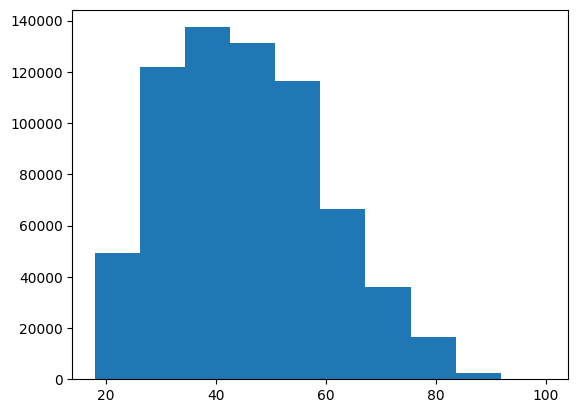

In [72]:
plt.hist(df["DrivAge"])
plt.show()

<Axes: >

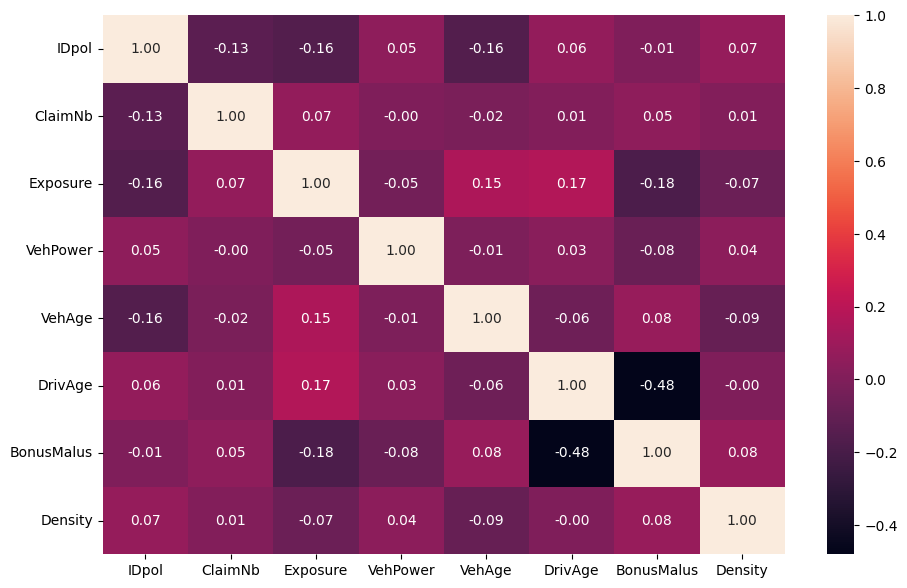

In [67]:
plt.figure(figsize=(11,7))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f")